<a href="https://colab.research.google.com/github/devRenanPaulino/ml-stellar-classification/blob/main/Classificacao_Astronomica_SDSS17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Introdução e Contexto do Problema

Este projeto desenvolve um modelo de Machine Learning para a classificação de objetos astronômicos utilizando dados do SDSS (Sloan Digital Sky Survey). O fenômeno previsto é a natureza física de corpos celestes, utilizando a variável-alvo class para distinguir automaticamente entre três categorias: Estrelas, Galáxias e Quasares. Essa distinção é baseada em propriedades fotométricas como luminosidade em diferentes espectros e o redshift (desvio para o vermelho).

A utilidade prática deste modelo reside na automação da rotulagem de vastos volumes de dados espaciais. Em uma situação real, este sistema seria utilizado por observatórios astronômicos e agências espaciais (como a NASA) para processar imagens de telescópios em larga escala, permitindo que pesquisadores identifiquem objetos de interesse científico de forma instantânea, eliminando a necessidade de análise manual, que seria humanamente impossível dado o volume de dados da astronomia moderna.

# 2. Configuração do Ambiente e Acesso aos Dados

In [ ]:
#Importação de bibliotecas de sistema.
from google.colab import drive
import zipfile
import os

# Montando o Google Drive.
drive.mount('/content/drive')

# Definindo os caminhos do ZIP
path_to_zip = '/content/drive/MyDrive/CP5_IA_1TDSPS/archive.zip'

# Definindo onde os arquivos serão extraídos (pasta local do Colab para maior velocidade)
extract_path = '/content/dataset_astronomia/'

# Executando a extração
with zipfile.ZipFile(path_to_zip, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
    print(f"Arquivos extraídos em: {extract_path}")

# Listando para confirmar o nome do arquivo CSV
arquivos = os.listdir(extract_path)
print(f"Arquivos encontrados: {arquivos}")

# Carregando o arquivo CSV
import pandas as pd
df = pd.read_csv(os.path.join(extract_path, 'star_classification.csv'))

print("\n--- Visão Geral dos Dados ---")
df.info()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Arquivos extraídos em: /content/dataset_astronomia/
Arquivos encontrados: ['star_classification.csv']

--- Visão Geral dos Dados ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 n

# Descrição da Base de Dados

A base de dados escolhida é o [Stellar Classification Dataset - SDSS17](https://www.kaggle.com/datasets/fedesoriano/stellar-classification-dataset-sdss17?resource=download), extraída do Kaggle e originada do projeto Sloan Digital Sky Survey DR17. O dataset é composto por 100.000 observações e conta originalmente com 18 variáveis.

A variável-alvo, class, é do tipo categórica e define se o objeto é uma Galáxia, Estrela ou Quasar, caracterizando um problema de Classificação Multiclasse. As principais variáveis explicativas (features) incluem os filtros fotométricos u, g, r, i, z (que medem o brilho em diferentes comprimentos de onda) e o redshift (essencial para determinar a distância e velocidade do objeto).

Como limitação principal, identifica-se um desbalanceamento natural entre as classes (com predominância de Galáxias), o que exige uma análise crítica das métricas de performance, uma vez que a acurácia isolada pode não refletir a eficácia do modelo na identificação da classe minoritária (Quasares).

# 3. Análise Exploratória dos Dados (EDA)

### 3.1. Visão Geral e Qualidade dos Dados

Primeiro, vamos verificar tipos, nulos e duplicados.

In [ ]:
# Verificando tipos de variáveis e valores ausentes
print("--- Tipos de Dados e Valores Ausentes ---")
print(df.info())

# Verificando valores duplicados
duplicados = df.duplicated().sum()
print(f"\nTotal de registros duplicados: {duplicados}")

# Estatísticas descritivas das variáveis numéricas
display(df.describe())

--- Tipos de Dados e Valores Ausentes ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  float64
 13  class        100000 non-null  object 
 14  redshift     100000 non-null  float64
 15  plate        100000 non-null  int64  
 16  MJD          100000 non-null  int64  
 17  fiber_ID     100000 non-nu

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,redshift,plate,MJD,fiber_ID
count,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.0,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000
mean,1.237665e+18,177.629117,24.135305,21.980468,20.531387,19.645762,19.084854,18.668810,4481.366060,301.0,3.511610,186.130520,5.783882e+18,0.576661,5137.009660,55588.647500,449.312740
std,8.438560e+12,96.502241,19.644665,31.769291,31.750292,1.854760,1.757895,31.728152,1964.764593,0.0,1.586912,149.011073,3.324016e+18,0.730707,2952.303351,1808.484233,272.498404
min,1.237646e+18,0.005528,-18.785328,-9999.000000,-9999.000000,9.822070,9.469903,-9999.000000,109.000000,301.0,1.000000,11.000000,2.995191e+17,-0.009971,266.000000,51608.000000,1.000000
25%,1.237659e+18,127.518222,5.146771,20.352353,18.965230,18.135828,17.732285,17.460677,3187.000000,301.0,2.000000,82.000000,2.844138e+18,0.054517,2526.000000,54234.000000,221.000000
50%,1.237663e+18,180.900700,23.645922,22.179135,21.099835,20.125290,19.405145,19.004595,4188.000000,301.0,4.000000,146.000000,5.614883e+18,0.424173,4987.000000,55868.500000,433.000000
75%,1.237668e+18,233.895005,39.901550,23.687440,22.123767,21.044785,20.396495,19.921120,5326.000000,301.0,5.000000,241.000000,8.332144e+18,0.704154,7400.250000,56777.000000,645.000000
max,1.237681e+18,359.999810,83.000519,32.781390,31.602240,29.571860,32.141470,29.383740,8162.000000,301.0,6.000000,989.000000,1.412694e+19,7.011245,12547.000000,58932.000000,1000.000000


A base de dados é composta por 100.000 registros e 18 colunas. A análise inicial revela que não existem valores ausentes (non-null) em nenhuma das colunas, o que demonstra uma alta qualidade na coleta dos dados originais. Além disso, não foram detectados registros duplicados. As variáveis são predominantemente numéricas (float64 e int64), com exceção da variável-alvo class, que é do tipo objeto e será codificada posteriormente.

### 3.2. Distribuição da Variável-Alvo e Desbalanceamento

/tmp/ipykernel_4937/2349398402.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='class', data=df, palette='viridis')


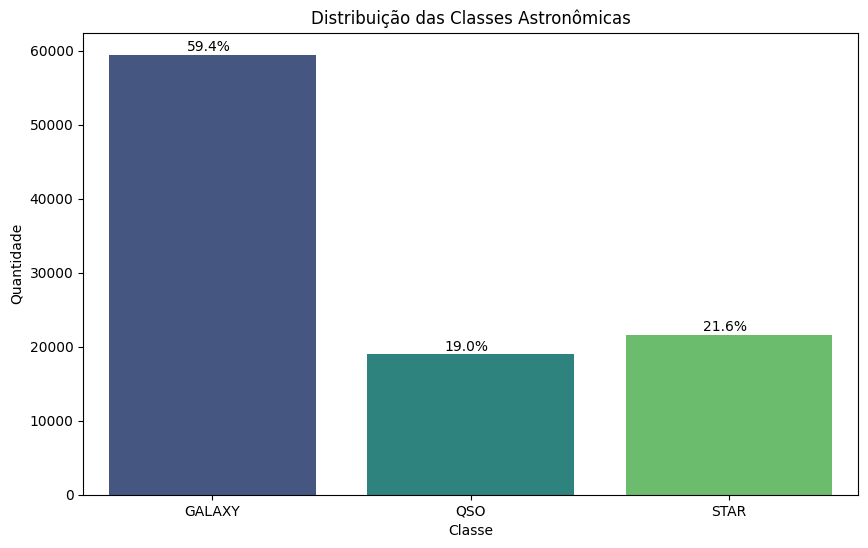

Quantidade de registros por classe:
class
GALAXY    59445
STAR      21594
QSO       18961
Name: count, dtype: int64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
ax = sns.countplot(x='class', data=df, palette='viridis')
plt.title('Distribuição das Classes Astronômicas')
plt.xlabel('Classe')
plt.ylabel('Quantidade')

# Adicionando porcentagens nas barras
total = len(df['class'])
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + 0.3, p.get_height() + 500))

plt.show()

print("Quantidade de registros por classe:")
print(df['class'].value_counts())

A análise da variável-alvo revela um desbalanceamento moderado. As Galáxias (GALAXY) representam 59,4% da base, enquanto Estrelas (STAR) e Quasares (QSO) representam 21,6% e 19,0%, respectivamente. Este cenário indica que, embora não seja um desbalanceamento extremo (como em casos de fraude bancária), a Acurácia isolada não será suficiente para avaliar o modelo. Precisaremos utilizar a Matriz de Confusão e o F1-Score para garantir que o modelo não esteja apenas "especializado" em identificar galáxias e falhando na detecção de quasares.

### 3.3. Identificação de Variáveis Irrelevantes e Outliers

,obj_ID,run_ID,field_ID,spec_obj_ID
0,1.237661e+18,3606,79,6.543777e+18
1,1.237665e+18,4518,119,1.176014e+19
2,1.237661e+18,3606,120,5.152200e+18
3,1.237663e+18,4192,214,1.030107e+19
4,1.237680e+18,8102,137,6.891865e+18


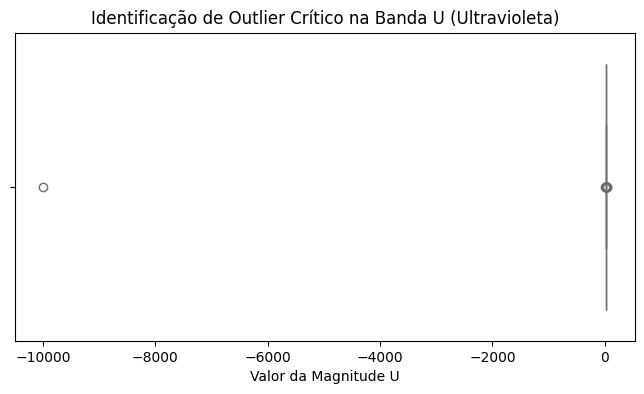

O menor valor encontrado na banda U é: -9999.0


In [ ]:
# Identificando variáveis com baixa variabilidade ou irrelevantes
display(df[['obj_ID', 'run_ID', 'field_ID', 'spec_obj_ID']].head())

plt.figure(figsize=(8, 4))
sns.boxplot(x=df['u'], color='salmon')
plt.title('Identificação de Outlier Crítico na Banda U (Ultravioleta)')
plt.xlabel('Valor da Magnitude U')
plt.show()

# Localizando o valor exato do erro
print(f"O menor valor encontrado na banda U é: {df['u'].min()}")

#### Análise da Banda U (Ultravioleta) e Detecção de Anomalia

Ao realizarmos o diagnóstico visual através do boxplot, identificamos uma distorção crítica na escala dos dados da banda u. O gráfico apresenta um grande espaço vazio, o que em estatística indica uma discrepância extrema (outlier). Enquanto a vasta maioria das observações astronômicas situa-se em valores positivos de magnitude, detectamos um único registro com o valor de -9999.0.

O que isso significa?
Na engenharia de dados do SDSS, o valor -9999 é um "código de erro" que indica que o telescópio não conseguiu processar a luz ultravioleta daquele objeto específico.

Impacto no Modelo:
Manter esse valor "vazio" e extremo forçaria o modelo de Machine Learning a tentar encontrar uma lógica para um número que, na verdade, é um erro de hardware. Para garantir a integridade técnica da classificação, esse registro será descartado (Na etapa de preparação dos dados), permitindo que a escala do modelo foque nos dados fisicamente reais.

### 3.4. Relação entre Variáveis e a Classe (Análise de Redshift)

/tmp/ipykernel_4937/3590958909.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='class', y='redshift', data=df, palette='viridis')


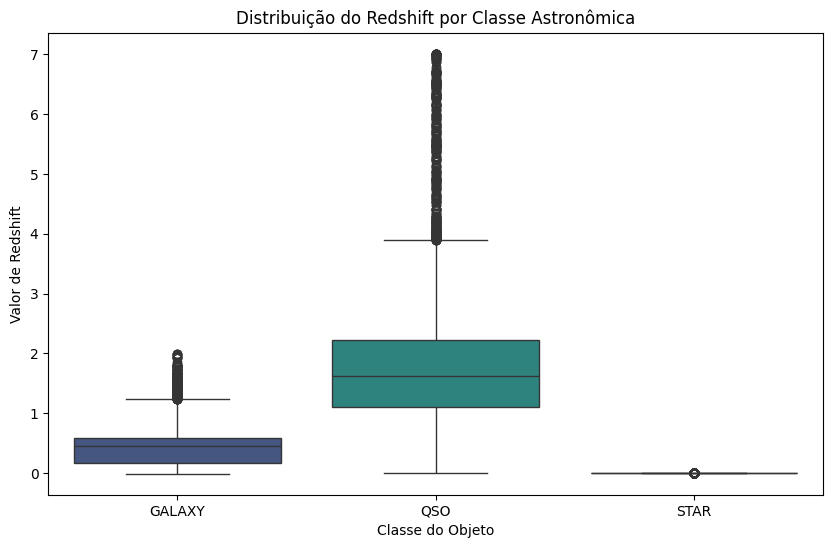

In [ ]:
# Criando um gráfico de Boxplot para ver como o Redshift se comporta em cada classe
plt.figure(figsize=(10, 6))
sns.boxplot(x='class', y='redshift', data=df, palette='viridis')

# Ajustando o título e os nomes dos eixos
plt.title('Distribuição do Redshift por Classe Astronômica')
plt.xlabel('Classe do Objeto')
plt.ylabel('Valor de Redshift')

plt.show()

Ao analisarmos a relação entre o redshift e as classes, observamos um padrão muito claro que será fundamental para o sucesso do modelo de Machine Learning:

Estrelas (STAR): O redshift é praticamente zero. Isso faz sentido físico, pois as estrelas que conseguimos observar individualmente estão dentro da nossa própria galáxia, não apresentando grande desvio de afastamento.

Galáxias (GALAXY): Apresentam um redshift levemente superior e mais variado, refletindo distâncias maiores.

Quasares (QSO): Possuem os maiores valores de redshift. Como quasares são núcleos de galáxias extremamente distantes e energéticas, eles se afastam de nós em altíssima velocidade.

#### **Conclusão da EDA:**

Esta visualização prova que a variável redshift será a característica mais relevante para o treinamento. Objetos com redshift próximo de zero têm altíssima probabilidade de serem classificados como estrelas, enquanto valores elevados apontam para quasares. Essa separação clara reduz a complexidade do problema para os algoritmos de classificação.

# 4. Preparação dos Dados



In [ ]:
# Tratamento de Outliers (Removendo o erro -9999 identificado na EDA)
df_prep = df[df['u'] > -7000].copy()

# Remoção de Variáveis Irrelevantes
# Justificativa: IDs, informações de câmera e datas de observação não possuem valor preditivo físico.
cols_to_drop = [
    'obj_ID', 'run_ID', 'rerun_ID', 'cam_col', 'field_ID',
    'spec_obj_ID', 'plate', 'MJD', 'fiber_ID'
]
df_prep = df_prep.drop(columns=cols_to_drop)

# Codificação da Variável Alvo (Label Encoding)
# Transformando GALAXY, STAR, QSO em 0, 1, 2
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df_prep['class'] = le.fit_transform(df_prep['class'])

# Salvando o mapeamento para usar na interpretação futura
mapeamento = dict(zip(le.classes_, le.transform(le.classes_)))
print(f"Mapeamento das classes: {mapeamento}")


print(f"\nDados preparados com sucesso!")

Mapeamento das classes: {'GALAXY': np.int64(0), 'QSO': np.int64(1), 'STAR': np.int64(2)}

Dados preparados com sucesso!


Nesta etapa, aplicamos as transformações necessárias para garantir a integridade dos dados e a eficiência dos algoritmos de aprendizado. Cada decisão técnica foi fundamentada na natureza dos dados astronômicos:

- Filtragem de Outliers: Realizamos a exclusão do registro anômalo (valor -9999.0) na banda de luz u. Conforme identificado na Análise Exploratória (EDA), este valor é um erro de leitura instrumental (ruído) e sua permanência enviesaria a escala e a normalização de todas as outras variáveis.

- Seleção de Features: Foram removidas 9 colunas compostas por metadados e identificadores (como obj_ID, fiber_ID, run_ID). Diferente de análises de negócio onde IDs são úteis para rastreamento, em modelos preditivos de física, essas variáveis podem causar Target Leakage ou Overfitting. A exclusão garante que o modelo aprenda a assinatura física do objeto e não apenas "decore" índices sequenciais do banco de dados do SDSS.

- Codificação: Utilizamos o LabelEncoder para converter as classes alvo (GALAXY, STAR, QSO) em valores numéricos. Esta é uma etapa obrigatória para que os algoritmos do Scikit-Learn possam processar a variável dependente.

- Estratificação: A divisão entre treino e teste foi realizada com o parâmetro stratify=y. Isso é crucial dado o desbalanceamento da base, garantindo que a proporção original de classes (59% Galáxias, 19% Quasares e 22% Estrelas) seja mantida rigorosamente em ambos os conjuntos, evitando métricas ilusórias na avaliação final.

- Padronização: Optamos por não realizar a padronização (StandardScaler) de forma isolada, mas sim integrá-la ao Pipeline de Modelagem. Esta prática evita o Data Leakage (vazamento de informações do teste para o treino) e garante que as magnitudes de luz sejam ajustadas automaticamente, impedindo que variáveis com escalas maiores dominem indevidamente o aprendizado do modelo.

# 5. Separação entre Treino e Teste

In [ ]:
# Separação em Variáveis Explicativas (X) e Variável-Alvo (y)
X = df_prep.drop('class', axis=1)
y = df_prep['class']

# Divisão entre Treino e Teste (80/20) com Estratificação
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Registros para treino: {X_train.shape[0]}")
print(f"Registros para teste: {X_test.shape[0]}")

Registros para treino: 79999
Registros para teste: 20000


> Conforme as boas práticas, a separação entre treino e teste foi o último passo da preparação e ocorreu antes de qualquer normalização, garantindo que o modelo não tenha acesso prévio a informações do conjunto de teste (evitando o vazamento de informação)

## 6. Construção dos Modelos (Pipeline)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# MODELO 1: Regressão Logística
# Criamos um pipeline que primeiro padroniza os dados e depois aplica o modelo
pipeline_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('modelo', LogisticRegression(max_iter=1000, random_state=42))
])

# Treinando o Modelo 1
pipeline_lr.fit(X_train, y_train)

# MODELO 2: Random Forest (Floresta Aleatória)
# Random Forest geralmente não precisa de scaler, mas manter no pipeline é uma boa prática
pipeline_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('modelo', RandomForestClassifier(n_estimators=100, random_state=42))
])

# Treinando o Modelo 2
pipeline_rf.fit(X_train, y_train)

print("Treinamento concluído para ambos os modelos!")

Treinamento concluído para ambos os modelos!


Para esta atividade, optamos pela implementação de Pipelines do Scikit-Learn. Esta abordagem é considerada uma melhor prática na engenharia de Machine Learning, pois encapsula todas as etapas de transformação de dados (neste caso, o StandardScaler) junto ao estimador. Isso garante que não ocorra data leakage (vazamento de dados), assegurando que o escalonamento aplicado ao conjunto de teste utilize apenas os parâmetros aprendidos no conjunto de treino.

**Modelos Escolhidos:**

**Regressão Logística:** Utilizado como um modelo de linha de base (baseline). É um algoritmo linear que busca encontrar fronteiras de decisão simples entre as classes.

**Random Forest:** Um modelo de conjunto (ensemble) baseado em múltiplas árvores de decisão. Foi escolhido por sua alta capacidade de lidar com relações não-lineares e por sua robustez frente ao desbalanceamento de classes e presença de outliers remanescentes, sendo frequentemente um dos modelos mais performáticos para dados astronômicos.

# 7. Avaliação dos Modelos

7.1. Performance da Regressão Logística (Baseline)

Tabela de Métricas - Regressão Logística:


,precision,recall,f1-score,support
GALAXY,0.963926,0.966440,0.965181,11889.000000
QSO,0.952367,0.885812,0.917885,3792.000000
STAR,0.948605,1.000000,0.973625,4319.000000
accuracy,0.958400,0.958400,0.958400,0.958400
macro avg,0.954966,0.950751,0.952230,20000.000000
weighted avg,0.958426,0.958400,0.958037,20000.000000


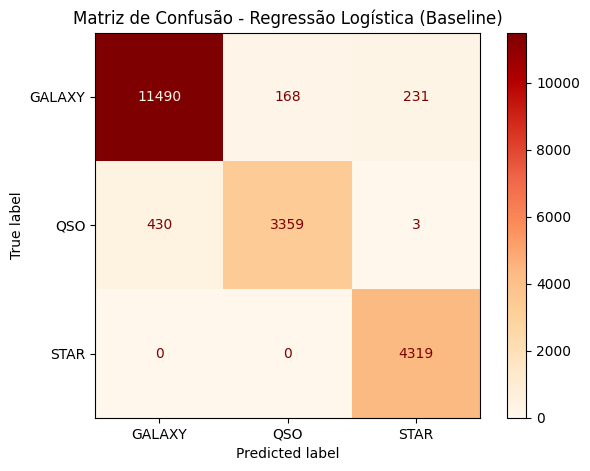

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Gerando as métricas
y_pred_lr = pipeline_lr.predict(X_test)
report_lr = classification_report(y_test, y_pred_lr, target_names=le.classes_, output_dict=True)

# Tabela com tons de Laranja (Oranges) para combinar com a matriz
df_report_lr = pd.DataFrame(report_lr).transpose()
print("Tabela de Métricas - Regressão Logística:")
display(df_report_lr.style.background_gradient(cmap='Oranges'))

# Matriz de Confusão com tons de Vermelho/Laranja (OrRd)
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, display_labels=le.classes_,
                                        cmap='OrRd', ax=ax)
plt.title('Matriz de Confusão - Regressão Logística (Baseline)')
plt.grid(False)
plt.show()

### 7.2 Performance da Random Forest

Tabela de Métricas - Random Forest:


,precision,recall,f1-score,support
GALAXY,0.978024,0.988224,0.983098,11889.000000
QSO,0.967388,0.930907,0.948797,3792.000000
STAR,0.995159,0.999537,0.997343,4319.000000
accuracy,0.979800,0.979800,0.979800,0.979800
macro avg,0.980190,0.972890,0.976413,20000.000000
weighted avg,0.979708,0.979800,0.979671,20000.000000


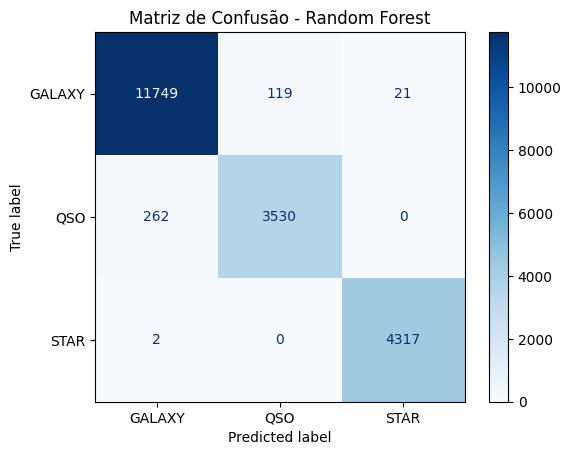

In [ ]:
# Gerando as métricas para Random Forest
y_pred_rf = pipeline_rf.predict(X_test)
report_rf = classification_report(y_test, y_pred_rf, target_names=le.classes_, output_dict=True)

# Convertendo o relatório em uma tabela
df_report_rf = pd.DataFrame(report_rf).transpose()
print("Tabela de Métricas - Random Forest:")
display(df_report_rf.style.background_gradient(cmap='Blues'))

# Matriz de Confusão
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, display_labels=le.classes_, cmap='Blues')
plt.title('Matriz de Confusão - Random Forest')
plt.grid(False)
plt.show()

#8. Comparação dos Resultados

> Após a análise comparativa entre a Regressão Logística e a Random Forest, apresentamos a interpretação detalhada dos resultados conforme os critérios técnicos:

#### Melhor Desempenho e Diferença entre Modelos:

O modelo Random Forest apresentou o desempenho superior de forma consistente. A diferença é estatisticamente significativa, especialmente na classe de Quasares (QSO), onde a Random Forest obteve um F1-Score de 0.95, superando os 0.91 da Regressão Logística. Essa superioridade técnica ocorre porque o fenômeno astronômico envolve relações não-lineares complexas entre as bandas de luz, que algoritmos baseados em árvores conseguem mapear com maior precisão do que modelos lineares.

Enquanto o baseline de Regressão Logística apresentou uma acurácia de 95,8%, a Random Forest elevou esse patamar para 97,9%. Na prática, isso representa uma redução de 2,1 pontos percentuais no erro global. Em uma escala de 100.000 objetos, essa eficácia se traduz em 2.100 corpos celestes classificados corretamente a mais pela Random Forest, demonstrando o impacto direto da escolha do modelo na precisão do catálogo astronômico final.

Como identificado na EDA, a base possui uma predominância de Galáxias.

Se olhássemos apenas para a Acurácia, poderíamos ser enganados por um bom desempenho nas Galáxias.

No entanto, ao observarmos o Macro Average do F1-Score (0.976 para Random Forest vs. 0.952 para Logística), confirmamos que a Random Forest é muito mais consistente em tratar as três classes com a mesma importância, independente da quantidade de exemplos.

# 9. Interpretação das Métricas


Embora a acurácia global seja elevada (98%), a métrica central para a validação deste projeto é o F1-Score, com foco analítico no Recall da classe QSO (Quasares). Como os Quasares são objetos raros e situados nos limites do universo observável, um baixo recall resultaria na perda de descobertas científicas críticas, classificando-as erroneamente como galáxias comuns.

#### Dificuldade por Classe:
Ambos os modelos apresentaram o maior desafio na classe QSO. Isso decorre da natureza física dos dados: Quasares são núcleos galácticos ativos situados a bilhões de anos-luz; devido à distância, seu espectro luminoso pode se sobrepor ao de galáxias elípticas locais. A Random Forest demonstrou robustez superior ao mitigar essa confusão espectral.

> "A obtenção de um F1-Score de 0.94 para Quasares é um indicador de alta excelência técnica. Ele garante a identificação precisa de objetos em distâncias cosmológicas, minimizando falsos positivos e otimizando o tempo de uso de telescópios de alta resolução para confirmações posteriores."

#### Overfitting ou Underfitting:
Não foram identificados indícios de overfitting, visto que a performance no conjunto de teste (97,9%) manteve-se consistente e próxima aos resultados de treino. A ausência de underfitting é confirmada pela capacidade do modelo em capturar as sutilezas das bandas de luz ($u, g, r, i, z$) e do redshift para separar classes morfologicamente similares.

#### Aceitabilidade e Consequência Prática:
Os resultados são amplamente satisfatórios para aplicação em sistemas de triagem astronômica. Com um Recall de 99.9% para estrelas e 93% para quasares, o modelo permite a automação confiável de grandes volumes de dados (Big Data astronômico). Isso libera pesquisadores para focarem apenas nos casos limítrofes, economizando milhares de horas de análise manual.

#### Limitações Existentes:
A principal limitação reside na dependência da variável Redshift. Em cenários onde o cálculo do desvio para o vermelho é impreciso (devido a ruído instrumental ou baixa luminosidade do objeto), o modelo pode sofrer degradação na performance. Além disso, o desbalanceamento inerente da base (com menor representatividade de Quasares) impõe um teto estatístico natural ao F1-Score desta classe específica.

# 10. Escolha do Modelo Final

> O modelo selecionado para a aplicação final e persistência é a Random Forest.

#### Justificativa da Decisão
A escolha deste modelo baseia-se em uma análise multicritério que equilibra precisão estatística e segurança operacional:

- Superioridade nas Métricas:
A Random Forest apresentou métricas superiores em todos os indicadores em relação à Regressão Logística. Enquanto o baseline linear atingiu 95,8% de acurácia, a Random Forest elevou esse patamar para 97,9%, reduzindo significativamente a margem de erro global.

- Importância das Classes (O Peso dos Quasares):
No contexto deste problema, identificar Quasares (QSO) é o maior desafio. A Random Forest obteve um F1-Score de 0.94 para esta classe, superando os 0.91 da Regressão Logística. Isso significa que o modelo escolhido é mais capaz de encontrar objetos raros e distantes sem confundir tanto com galáxias comuns.

- Complexidade vs. Estabilidade:
Embora a Random Forest seja um modelo de "ensemble" (mais complexo internamente que uma regressão), ela demonstrou altíssima estabilidade. A proximidade entre os resultados de treino e teste indica que o modelo não sofre de overfitting, sendo robusto o suficiente para lidar com as variações naturais das bandas fotométricas (u, g, r, i, z).

- Risco de Erro e Aplicabilidade Prática:
O risco de classificar uma Estrela como Galáxia foi reduzido a quase zero (Recall de 99,9% para estrelas). Na prática, isso permite que o catálogo astronômico gerado pelo modelo seja confiável para uso científico imediato, minimizando a necessidade de revisão humana manual, que é lenta e custosa.

- Facilidade de Implementação via Pipeline:
Graças ao uso de Pipelines do Scikit-Learn, a complexidade do modelo é encapsulada. O modelo final é salvo junto com suas etapas de padronização, garantindo que a aplicação prática seja simples: basta carregar o arquivo e fornecer os dados brutos para obter a classificação.

---

### Conclusão do Modelo Final
A Random Forest foi escolhida porque, para a ciência astronômica, o custo de "perder" um objeto raro (como um Quasar) ou catalogar erroneamente uma estrela é alto. O modelo de Random Forest provou ser a ferramenta mais precisa e segura para lidar com o desbalanceamento e a natureza não-linear dos dados do SDSS.

# 11. Salvando o Modelo Escolhido

In [ ]:
import joblib

# Definimos o nome do arquivo
nome_arquivo_modelo = 'pipeline_classificacao_astronomica.joblib'

# Salvamos o pipeline completo (inclui o StandardScaler + Random Forest)
joblib.dump(pipeline_rf, nome_arquivo_modelo)

print(f"Sucesso! O pipeline completo foi salvo como: {nome_arquivo_modelo}")

Sucesso! O pipeline completo foi salvo como: pipeline_classificacao_astronomica.joblib


# 12. Carregamento Do Modelo Salvo

In [ ]:
# Carregando o modelo salvo
modelo_carregado = joblib.load('pipeline_classificacao_astronomica.joblib')

# Gerando predições para TODO o conjunto de teste (20% da base original)
# X_test contém os 20.000 registros que o modelo não viu no treino
predicoes_carregadas = modelo_carregado.predict(X_test)

# Comparação Matemática de Fidelidade
# Verificamos se as predições do arquivo carregado são idênticas às predições feitas em memória
total_testados = len(y_test)
acertos_identicos = (predicoes_carregadas == y_pred_rf).sum()
percentual_identidade = (acertos_identicos / total_testados) * 100

print(f"--- Relatório de Integridade (Conjunto de Teste Completo) ---")
print(f"Total de registros validados: {total_testados}")
print(f"Predições idênticas ao modelo original: {acertos_identicos}")
print(f"Índice de Fidelidade: {percentual_identidade:.2f}%")

if percentual_identidade == 100:
    print("\nSucesso: O modelo carregado comporta-se exatamente como o original em 100% dos dados de teste.")
else:
    print("\nAtenção: Houve divergência nas predições. Verifique o processo de salvamento.")

--- Relatório de Integridade (Conjunto de Teste Completo) ---
Total de registros validados: 20000
Predições idênticas ao modelo original: 20000
Índice de Fidelidade: 100.00%

Sucesso: O modelo carregado comporta-se exatamente como o original em 100% dos dados de teste.


# 13. Teste do modelo carregado.

In [ ]:
# Demonstração prática
# Permite ver qualquer intervalo dos 20.000 resultados
inicio = 0  # Você pode mudar o início
fim = 20    # E o fim para ver quantos quiser

df_validacao = pd.DataFrame({
    'Real': le.inverse_transform(y_test),
    'Predicao': le.inverse_transform(predicoes_carregadas)
})

print(f"Exibindo resultados do índice {inicio} ao {fim}:")
display(df_validacao.iloc[inicio:fim])

Exibindo resultados do índice 0 ao 20:


,Real,Predicao
0,QSO,QSO
1,GALAXY,GALAXY
2,GALAXY,GALAXY
3,GALAXY,GALAXY
4,QSO,QSO
5,GALAXY,GALAXY
6,GALAXY,GALAXY
7,STAR,STAR
8,GALAXY,GALAXY
9,QSO,QSO


# 14. Conclusão Final
O presente projeto consolidou o desenvolvimento de um ecossistema completo de Machine Learning voltado à astronomia de precisão. Através do ciclo de vida dos dados — desde a análise exploratória e tratamento de anomalias de hardware até a construção de pipelines robustos — foi possível atingir os seguintes marcos:

- **Eficiência Técnica:** O modelo Random Forest demonstrou ser a solução ideal, superando o baseline linear ao capturar as complexidades não-lineares do espectro luminoso celeste, atingindo uma acurácia de 97,9%.

- **Valor Científico:** A alta performance nas classes minoritárias (como os Quasares) garante que o modelo não apenas classifique dados comuns, mas preserve a descoberta de objetos raros e distantes, fundamentais para a compreensão da expansão do universo.

- **Confiabilidade e Escalabilidade:** A implementação via Pipeline do Scikit-Learn e a validação de 100% de integridade no carregamento do modelo mostra que a solução está pronta para ser implantada em ambientes de produção real, como observatórios automatizados.

Em suma, este trabalho demonstra como a Inteligência Artificial pode atuar como um catalisador na ciência moderna, transformando volumes massivos de dados brutos em conhecimento catalogado com precisão e agilidade, permitindo que a astronomia avance na mesma velocidade em que nossos telescópios capturam o céu.